In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("train.csv")

In [ ]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Dataset Shape

In this step, we will check the number of rows and columns present in our dataset.

In [ ]:
df.shape

(1460, 81)

### Observation

The dataset contains 1460 rows and 81 columns. Each row represents a house, and each column represents a feature or information about the house.

### Dataset Information

In this step, we will check the column names, data types, and non-null values using the info() function.

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

### Observation

The dataset contains numerical and categorical columns. Some columns have missing values, which will be checked further during data analysis and cleaning.

### Missing Values Analysis

In this step, we will identify the missing values in each column of the dataset.

In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


### Observation

The dataset contains missing values in multiple columns. Some columns have a large number of missing values, while some columns have very few or no missing values. These missing values need to be examined before further analysis.

In [ ]:
missing_data = df.isnull().sum()

missing_percent = (missing_data / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing_data,
    "Missing Percentage": missing_percent
})

missing_table = missing_table[missing_table["Missing Count"] > 0]

missing_table = missing_table.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_table

,Missing Count,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


### Observation

The dataset contains missing values in 19 columns out of 81 columns. PoolQC has the highest missing percentage of 99.52%, followed by MiscFeature (96.30%), Alley (93.77%), and Fence (80.75%). Electrical has only one missing value. Some missing values may indicate that a feature is absent rather than unknown. These values need to be handled carefully during analysis.

## Variable Classification

In this step, we will classify the dataset columns into numerical, categorical, and ordinal variables. We will also check the unique values and examples of each column.

In [ ]:
# Separate numerical and categorical columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

# Define ordinal categories
ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

# Convert ordinal columns into ordered categories
for column in ordinal_map:
    df[column] = pd.Categorical(
        df[column],
        categories=ordinal_map[column],
        ordered=True
    )

# Create a variable summary table
variable_summary = pd.DataFrame({
    "Column Name": df.columns,
    "Type": [
        "Ordinal" if col in ordinal_map or col == "OverallQual"
        else "Numerical" if col in numeric_cols
        else "Categorical"
        for col in df.columns
    ],
    "Unique Values": [df[col].nunique() for col in df.columns],
    "Example Values": [
        list(df[col].dropna().unique()[:5])
        for col in df.columns
    ]
})

variable_summary

,Column Name,Type,Unique Values,Example Values
0,Id,Numerical,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,Numerical,15,"[60, 20, 70, 50, 190]"
2,MSZoning,Categorical,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250, 9550, 14260]"
...,...,...,...,...
76,MoSold,Numerical,12,"[2, 5, 9, 12, 10]"
77,YrSold,Numerical,5,"[2008, 2007, 2006, 2009, 2010]"
78,SaleType,Categorical,9,"[WD, New, COD, ConLD, ConLI]"
79,SaleCondition,Categorical,6,"[Normal, Abnorml, Partial, AdjLand, Alloca]"


## Descriptive Statistics

Descriptive statistics help us understand the distribution, average, minimum, maximum, and spread of numerical data.

In [ ]:
df.describe()


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
df["SalePrice"].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


In [ ]:
columns = ["SalePrice", "GrLivArea", "LotArea"]

for column in columns:
    print("\nStatistics for", column)

    print("Mean:", df[column].mean())
    print("Median:", df[column].median())
    print("Mode:", df[column].mode()[0])
    print("Standard Deviation:", df[column].std())
    print("Variance:", df[column].var())
    print("Range:", df[column].max() - df[column].min())
    print("IQR:", df[column].quantile(0.75) - df[column].quantile(0.25))
    print("Skewness:", df[column].skew())
    print("Kurtosis:", df[column].kurt())


Statistics for SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

Statistics for GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

Statistics for LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


### Observation

The average SalePrice is higher than the median, indicating a right-skewed distribution. The data also shows variation in house prices, with some expensive houses affecting the average. This suggests that the dataset may contain high-value outliers.

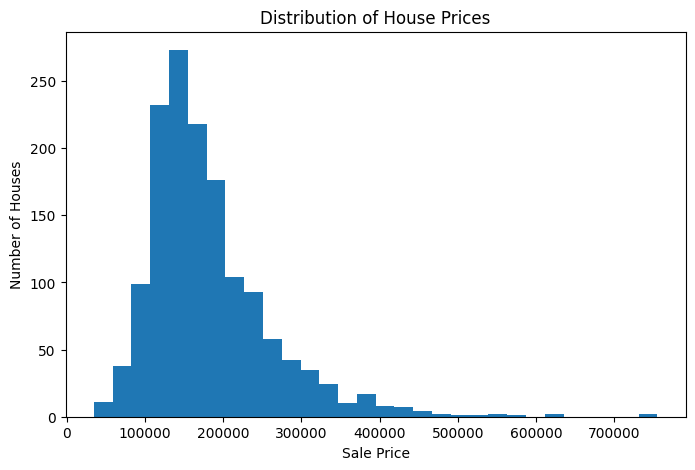

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df["SalePrice"], bins=30)

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")

plt.show()

### Observation – SalePrice Distribution

The histogram shows a right-skewed distribution of SalePrice. Most houses are concentrated in the lower and middle price ranges, while a few houses have very high prices. This creates a long tail on the right side of the graph. The distribution is not symmetrical and may contain high-price outliers.

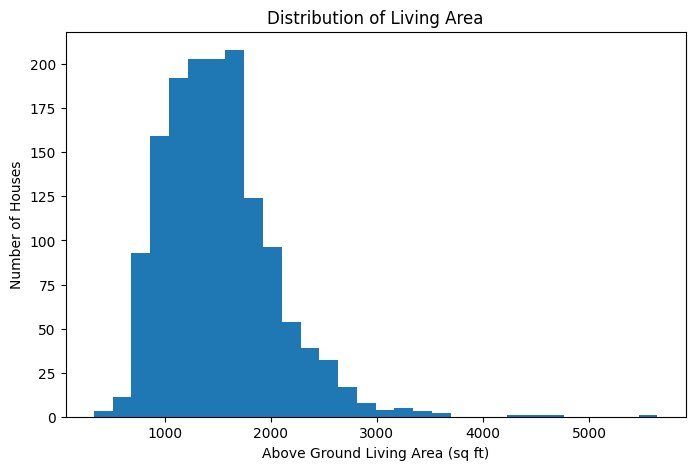

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df["GrLivArea"], bins=30)

plt.title("Distribution of Living Area")
plt.xlabel("Above Ground Living Area (sq ft)")
plt.ylabel("Number of Houses")

plt.show()

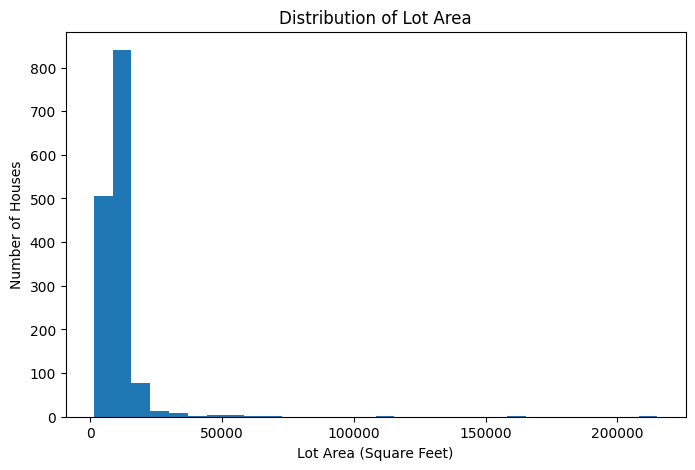

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df["LotArea"], bins=30)

plt.title("Distribution of Lot Area")
plt.xlabel("Lot Area (Square Feet)")
plt.ylabel("Number of Houses")

plt.show()

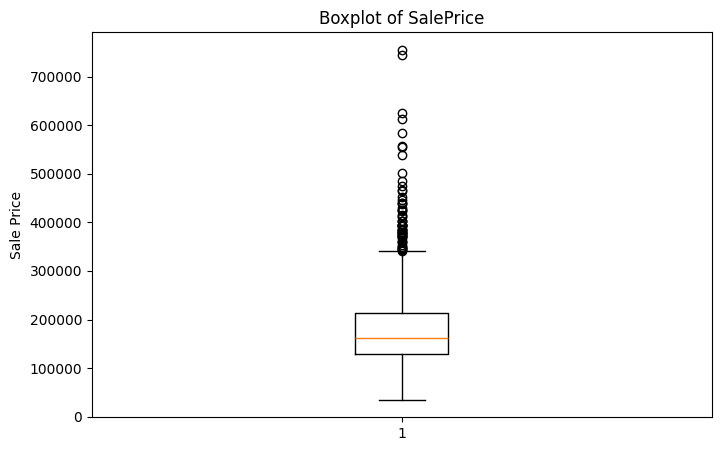

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["SalePrice"])

plt.title("Boxplot of SalePrice")
plt.ylabel("Sale Price")

plt.show()

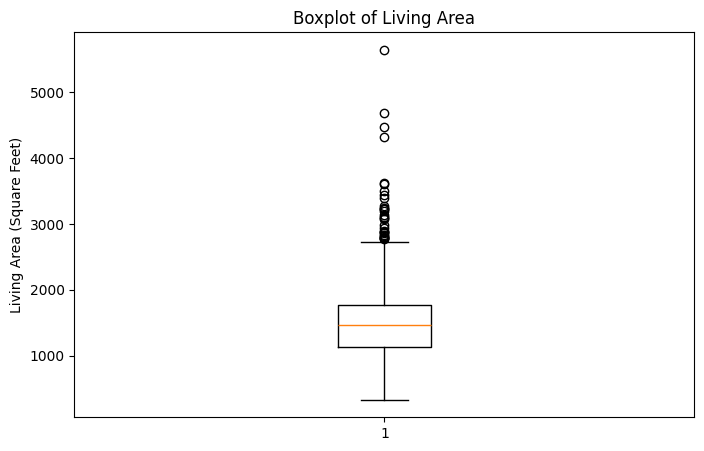

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["GrLivArea"])

plt.title("Boxplot of Living Area")
plt.ylabel("Living Area (Square Feet)")

plt.show()

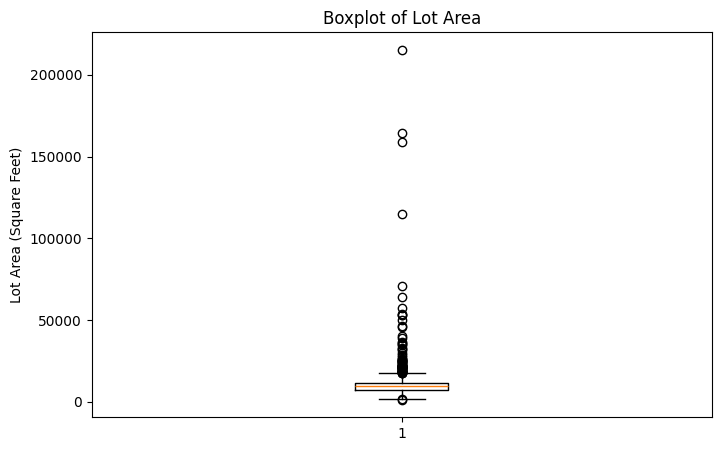

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["LotArea"])

plt.title("Boxplot of Lot Area")
plt.ylabel("Lot Area (Square Feet)")

plt.show()

## Correlation Analysis

Correlation is used to understand the relationship between numerical variables. It shows whether two variables move together, in opposite directions, or have a weak relationship.

In [ ]:
correlation = df.select_dtypes(include=np.number).corr()

correlation["SalePrice"].sort_values(ascending=False)

,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


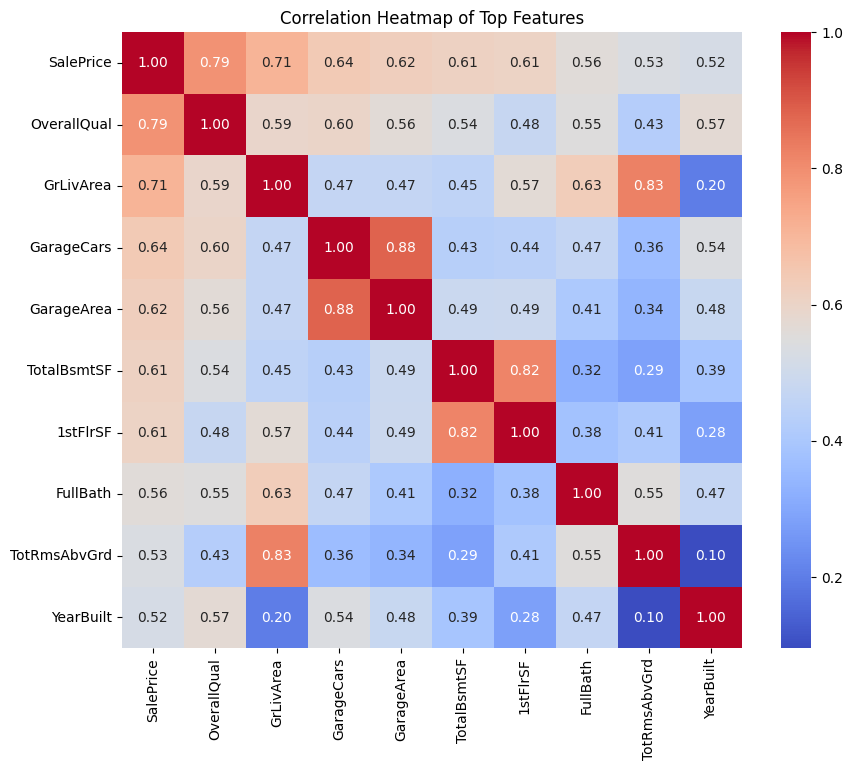

In [ ]:
top_corr = correlation["SalePrice"].abs().sort_values(ascending=False).head(10).index

plt.figure(figsize=(10, 8))

sns.heatmap(df[top_corr].corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Top Features")

plt.show()

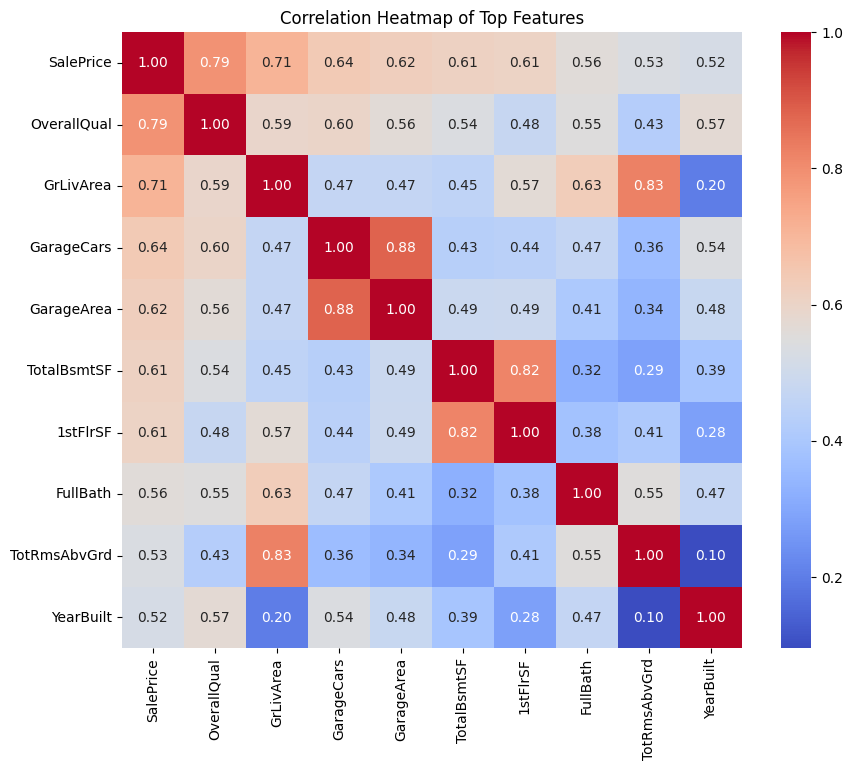

In [ ]:
top_corr = correlation["SalePrice"].abs().sort_values(ascending=False).head(10).index

plt.figure(figsize=(10, 8))

sns.heatmap(df[top_corr].corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Top Features")

plt.show()

Step 8: Outlier Detection

In this step, we identify unusual values in the dataset using the IQR and Z-Score methods.

In [ ]:

# Step 8: Outlier Detection

# Function to detect outliers using IQR
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return series[(series < lower) | (series > upper)].index


# Function to detect outliers using Z-Score
def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()

    return series[z.abs() > threshold].index


# Compare both methods
for column in ["GrLivArea", "SalePrice"]:

    iqr_result = iqr_outliers(df[column])
    zscore_result = zscore_outliers(df[column])

    print("\nColumn:", column)

    print("IQR Outliers:", len(iqr_result))
    print("Z-Score Outliers:", len(zscore_result))

    overlap = set(iqr_result).intersection(set(zscore_result))

    print("Common Outliers:", len(overlap))



Column: GrLivArea
IQR Outliers: 31
Z-Score Outliers: 16
Common Outliers: 16

Column: SalePrice
IQR Outliers: 61
Z-Score Outliers: 22
Common Outliers: 22



### Step 8.2: Visualizing Outliers

In this step, we use boxplots and scatter plots to visualize unusual house sizes and selling prices.


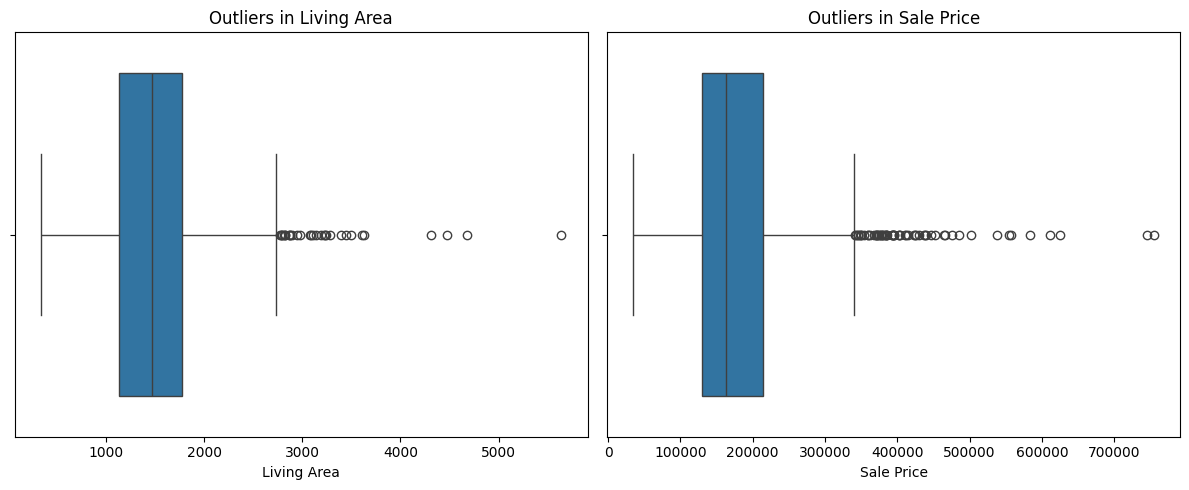

In [ ]:

# Step 8.2: Boxplots for Outlier Detection

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x=df["GrLivArea"])
plt.title("Outliers in Living Area")
plt.xlabel("Living Area")

plt.subplot(1, 2, 2)
sns.boxplot(x=df["SalePrice"])
plt.title("Outliers in Sale Price")
plt.xlabel("Sale Price")

plt.tight_layout()
plt.show()



### Step 8.3: Scatter Plot for Outlier Visualization

This scatter plot shows the relationship between house living area and sale price. Potential outliers are highlighted using the IQR and Z-Score methods.


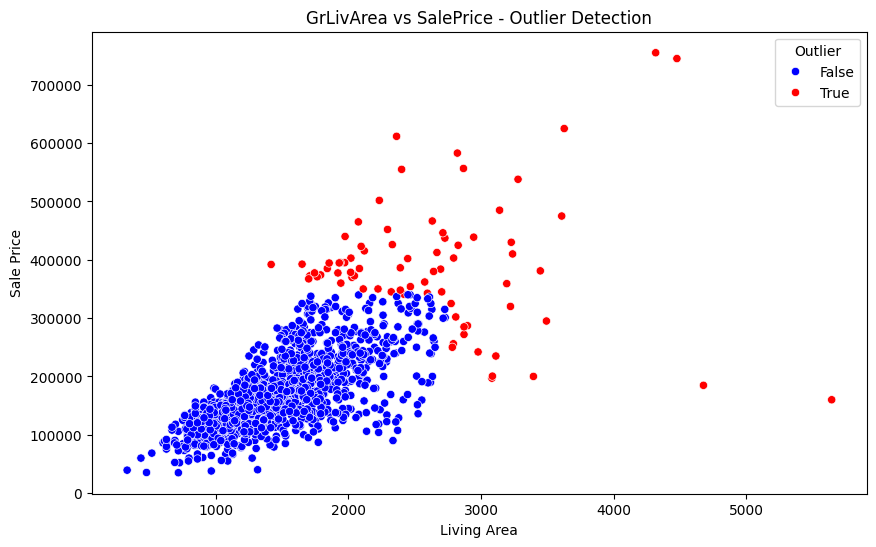

In [ ]:

# Step 8.3: Scatter Plot Highlighting Outliers

# Find outliers in both columns
area_outliers = set(iqr_outliers(df["GrLivArea"]))
price_outliers = set(iqr_outliers(df["SalePrice"]))

# Combine both outlier groups
outlier_indices = area_outliers.union(price_outliers)

# Create a column to identify outliers
df["Outlier"] = df.index.isin(outlier_indices)

# Plot the scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="Outlier",
    palette={False: "blue", True: "red"}
)

plt.title("GrLivArea vs SalePrice - Outlier Detection")
plt.xlabel("Living Area")
plt.ylabel("Sale Price")
plt.legend(title="Outlier")
plt.show()


Step 8.4: Investigation of Outliers

In this step, we examine unusual house records to determine whether they are genuine observations or possible data errors.

In [ ]:

# Display houses with very large living areas

large_houses = df[df["GrLivArea"] > 4000]

print("Number of houses with living area above 4000:")
print(len(large_houses))

print("\nDetails of these houses:")

print(large_houses[["GrLivArea", "SalePrice", "OverallQual", "YearBuilt"]])


Number of houses with living area above 4000:
4

Details of these houses:
      GrLivArea  SalePrice  OverallQual  YearBuilt
523        4676     184750           10       2007
691        4316     755000           10       1994
1182       4476     745000           10       1996
1298       5642     160000           10       2008



## Step 9: Data Quality Checks

In this step, we check the dataset for duplicate records, inconsistent categories, missing values and impossible values.


In [ ]:

# Step 9.1: Checking Duplicate Records

# Count duplicate rows
dup_count = df.duplicated().sum()

print("Number of duplicate records:", dup_count)

# Remove duplicates if present
if dup_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed successfully.")

else:
    print("No duplicate records found.")

# Display updated dataset shape
print("Updated dataset shape:", df.shape)


Number of duplicate records: 0
No duplicate records found.
Updated dataset shape: (1460, 82)



### Step 9.2: Checking Inconsistent Categories

In this step, we identify inconsistent category labels caused by different letter cases and extra spaces.


In [ ]:


# Step 9.2: Checking Inconsistent Categories

categorical_cols = df.select_dtypes(include="object").columns

found = False

for column in categorical_cols:

    values = df[column].dropna().unique()
    grouped_values = {}

    for value in values:
        clean_value = value.strip().lower()

        if clean_value not in grouped_values:
            grouped_values[clean_value] = []

        grouped_values[clean_value].append(value)

    for key, group in grouped_values.items():
        if len(group) > 1:
            found = True
            print("Column:", column)
            print("Inconsistent values:", group)

if not found:
    print("No inconsistent category values found.")


No inconsistent category values found.



### Step 9.3: Missing Value Analysis

In this step, we identify missing values in the dataset and calculate their percentages to understand the extent of missing information.


In [ ]:

# Step 9.3: Checking Missing Values

# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (missing_count / len(df)) * 100

# Create a summary table
missing_data = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

# Display only columns having missing values
missing_data = missing_data[missing_data["Missing Values"] > 0]

# Sort in descending order
missing_data = missing_data.sort_values(
    by="Missing Values",
    ascending=False
)

print("Columns with Missing Values:")
display(missing_data)


Columns with Missing Values:


,Missing Values,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945



### Step 9.3 (Part 2): Handling Categorical Missing Values

Missing values in selected categorical columns are replaced with "None" because they represent the absence of that feature.


In [ ]:

# Handle missing categorical values

categorical_missing_cols = [
    "PoolQC",
    "Alley",
    "Fence",
    "FireplaceQu",
    "GarageType"
]

for column in categorical_missing_cols:
    df[column] = df[column].fillna("None")

print("Missing categorical values handled successfully!")

print("\nRemaining missing values:")
print(df[categorical_missing_cols].isnull().sum())


Missing categorical values handled successfully!

Remaining missing values:
PoolQC         0
Alley          0
Fence          0
FireplaceQu    0
GarageType     0
dtype: int64



### Step 9.4: Handling Numerical Missing Values

In this step, we identify numerical columns containing missing values and select an appropriate strategy to handle them.


In [ ]:

# Step 9.4: Check Numerical Missing Values

numeric_missing = df.select_dtypes(include="number").isnull().sum()

numeric_missing = numeric_missing[numeric_missing > 0]

print("Numerical Columns with Missing Values:")
display(numeric_missing)


Numerical Columns with Missing Values:


,0
LotFrontage,259
MasVnrArea,8
GarageYrBlt,81


In [ ]:
numeric_missing = df.select_dtypes(include="number").isnull().sum()
numeric_missing = numeric_missing[numeric_missing > 0]

print("Numerical Columns with Missing Values:")
display(numeric_missing)

Numerical Columns with Missing Values:


,0
LotFrontage,259
MasVnrArea,8
GarageYrBlt,81



### Step 9.4: Handling Numerical Missing Values

In this step, missing numerical values are handled using neighborhood-based median imputation and zero replacement for absent house features.


In [ ]:

# Step 9.4: Handling Numerical Missing Values

# Fill LotFrontage using neighborhood median
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)

# Fill remaining LotFrontage values using overall median
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())

# Fill missing Masonry Veneer Area with 0
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

# Fill missing Garage Year Built with 0
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)

print("Numerical missing values handled successfully!")

# Verify remaining missing values
print("\nRemaining missing values:")
print(df[["LotFrontage", "MasVnrArea", "GarageYrBlt"]].isnull().sum())


Numerical missing values handled successfully!

Remaining missing values:
LotFrontage    0
MasVnrArea     0
GarageYrBlt    0
dtype: int64


In [ ]:

# Step 9.4: Handling Numerical Missing Values

# Fill LotFrontage using neighborhood median
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)

# Fill any remaining LotFrontage values
df["LotFrontage"] = df["LotFrontage"].fillna(
    df["LotFrontage"].median()
)

# Fill missing Masonry Veneer Area
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

# Fill missing Garage Year Built
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)

print("Numerical missing values handled successfully!")


Numerical missing values handled successfully!


In [ ]:

# Step 9.5: Final Missing Value Verification

remaining_missing = df.isnull().sum()

remaining_missing = remaining_missing[remaining_missing > 0]

print("Remaining Missing Values:")

if len(remaining_missing) == 0:
    print("No missing values remaining!")
else:
    display(remaining_missing.sort_values(ascending=False))

print("\nTotal missing values:", df.isnull().sum().sum())


Remaining Missing Values:


,0
MiscFeature,1406
MasVnrType,872
GarageCond,81
GarageFinish,81
GarageQual,81
BsmtFinType2,38
BsmtExposure,38
BsmtCond,37
BsmtQual,37
BsmtFinType1,37



Total missing values: 2709


In [ ]:

# Step 9.6: Checking Impossible Values

# Check houses built after their sale year
invalid_years = df[df["YearBuilt"] > df["YrSold"]]

print("Houses built after sale year:")
print(len(invalid_years))

# Check negative area values
area_columns = [
    "GrLivArea",
    "LotArea",
    "TotalBsmtSF",
    "GarageArea",
    "MasVnrArea",
    "LotFrontage"
]

print("\nNegative Area Values:")

for column in area_columns:
    negative_count = (df[column] < 0).sum()
    print(column, ":", negative_count)

# Display suspicious year records
if len(invalid_years) > 0:
    display(invalid_years[["YearBuilt", "YrSold"]])


Houses built after sale year:
0

Negative Area Values:
GrLivArea : 0
LotArea : 0
TotalBsmtSF : 0
GarageArea : 0
MasVnrArea : 0
LotFrontage : 0


In [ ]:

# Step 9.7: Final Data Quality Summary

print("FINAL DATA QUALITY REPORT")
print("-------------------------")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("Duplicate Rows:", df.duplicated().sum())

print("Total Missing Values:", df.isnull().sum().sum())

print("Invalid Year Records:", len(invalid_years))

print("\nData Quality Check Completed!")


FINAL DATA QUALITY REPORT
-------------------------
Total Rows: 1460
Total Columns: 82
Duplicate Rows: 0
Total Missing Values: 2709
Invalid Year Records: 0

Data Quality Check Completed!



# Step 10: Final Dashboard and Storytelling

The final dashboard combines four important visualizations to summarize the major findings of the House Price Exploratory Data Analysis project.


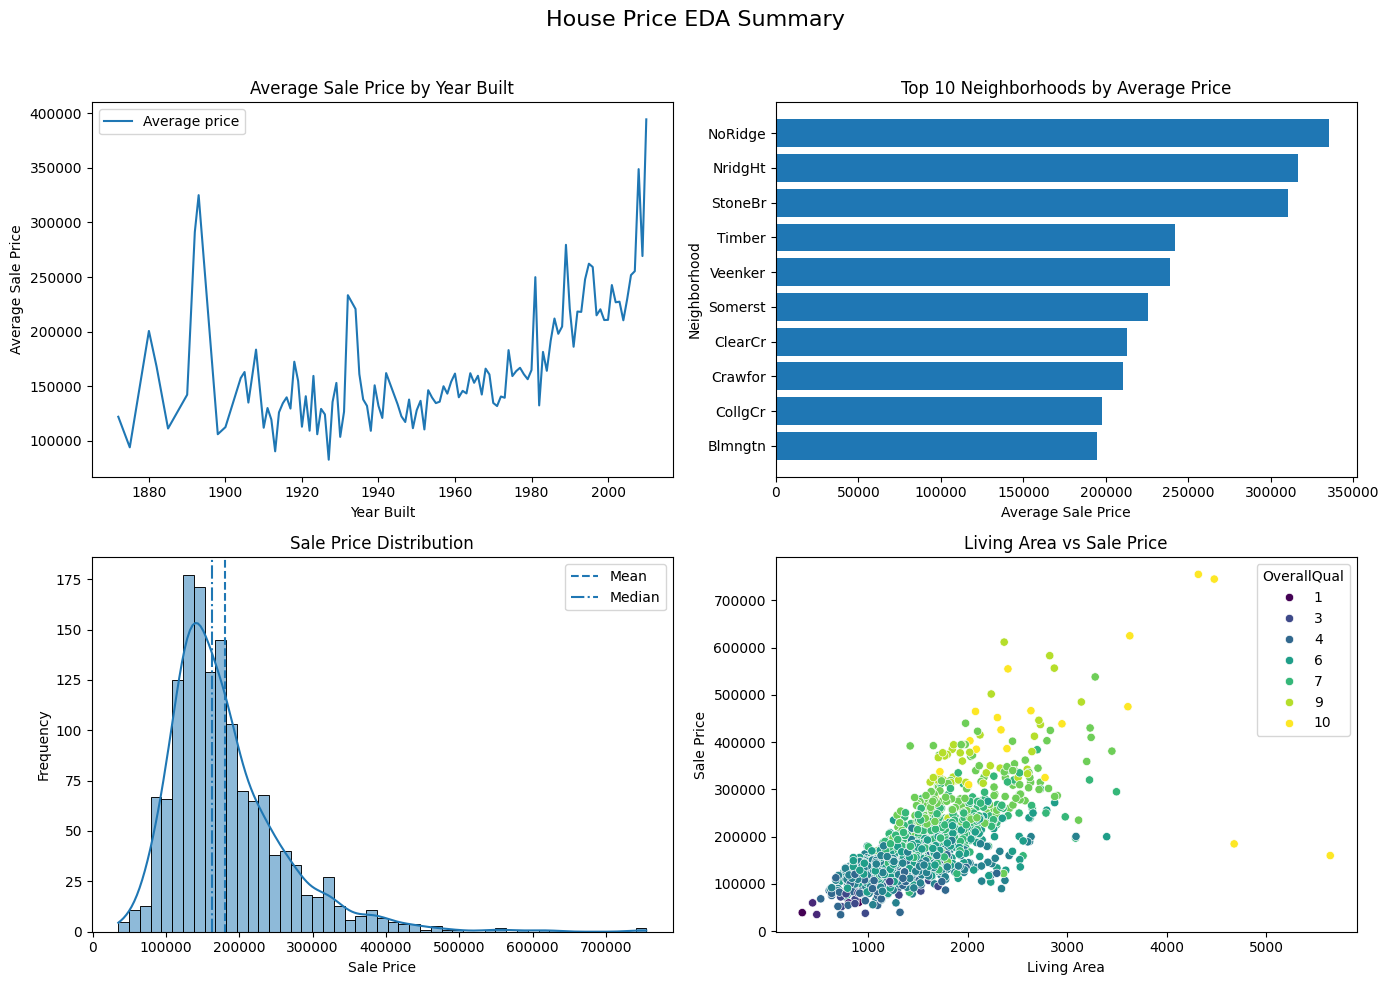

Final Dashboard Created Successfully!
Dashboard saved as eda_dashboard.png


In [ ]:

# Step 10: Final House Price EDA Dashboard

# Create a figure with 2 rows and 2 columns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ----------------------------------
# Panel 1: Average Sale Price by Year
# ----------------------------------

yearly_price = df.groupby("YearBuilt")["SalePrice"].mean()

axes[0, 0].plot(
    yearly_price.index,
    yearly_price.values,
    label="Average price"
)

axes[0, 0].set_title("Average Sale Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")
axes[0, 0].legend()

# ----------------------------------
# Panel 2: Top 10 Neighborhoods
# ----------------------------------

neighborhood_price = (
    df.groupby("Neighborhood")["SalePrice"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

axes[0, 1].barh(
    neighborhood_price.index,
    neighborhood_price.values
)

axes[0, 1].set_title("Top 10 Neighborhoods by Average Price")
axes[0, 1].set_xlabel("Average Sale Price")
axes[0, 1].set_ylabel("Neighborhood")

# ----------------------------------
# Panel 3: Sale Price Distribution
# ----------------------------------

sns.histplot(
    df["SalePrice"],
    kde=True,
    ax=axes[1, 0]
)

mean_price = df["SalePrice"].mean()
median_price = df["SalePrice"].median()

axes[1, 0].axvline(
    mean_price,
    linestyle="--",
    label="Mean"
)

axes[1, 0].axvline(
    median_price,
    linestyle="-.",
    label="Median"
)

axes[1, 0].set_title("Sale Price Distribution")
axes[1, 0].set_xlabel("Sale Price")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].legend()

# ----------------------------------
# Panel 4: Living Area vs Sale Price
# ----------------------------------

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    palette="viridis",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Living Area vs Sale Price")
axes[1, 1].set_xlabel("Living Area")
axes[1, 1].set_ylabel("Sale Price")

# ----------------------------------
# Final Dashboard
# ----------------------------------

fig.suptitle(
    "House Price EDA Summary",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save dashboard
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")

plt.show()

print("Final Dashboard Created Successfully!")
print("Dashboard saved as eda_dashboard.png")


# Conclusion – House Price Exploratory Data Analysis

In this project, Exploratory Data Analysis (EDA) was performed on the Ames Housing Dataset to understand the factors affecting house selling prices.

The following observations were made:

1. **Overall Quality:** OverallQual showed a strong positive correlation with SalePrice (approximately 0.79). This indicates that higher-quality houses generally have higher selling prices.

2. **Living Area:** GrLivArea showed a positive correlation with SalePrice (approximately 0.71), suggesting that larger living areas are generally associated with higher prices.

3. **Correlation Analysis:** The correlation heatmap helped identify relationships between important numerical features.

4. **Outlier Detection:** IQR and Z-Score methods were used to identify unusual observations. Some houses had very large living areas but comparatively low selling prices, so these records were investigated rather than automatically deleted.

5. **Data Quality:** Duplicate records, inconsistent category labels and missing values were examined. Missing values were handled using appropriate strategies.

6. **Final Dashboard:** Four visualizations were combined to summarize yearly price trends, expensive neighborhoods, price distribution and the relationship between living area and selling price.

**Overall Conclusion:**

This project helped demonstrate how Python libraries such as Pandas, NumPy, Matplotlib and Seaborn can be used to explore, clean, analyze and visualize real-world housing data.

The analysis shows that house quality, living area and neighborhood are important factors associated with house selling prices.